# sim&seg and pilot video tests
All functions from `~/inia/src/video_eval.py`.

In [1]:
%pylab inline
%load_ext autoreload
%autoreload 2

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [3]:
import sys
sys.path.insert(0, "/var/tmp/jiehyun_tmp/cv2_headless")   # headless cv2 (for chimera12 only)
sys.path.insert(0, "/home/jiehyun.kim001/inia/src")
%matplotlib inline
from video_eval import *
S.setup_notebook(require_hf_token=True)

[SPLEENUS] notebook set up (seed=42, env=/home/jiehyun.kim001/SPLEENUS/team-SAMv3-impact/.env.local)


In [4]:
ROOT   = f"{SIM}/RUS"                                      # 6 sim&seg slices with spleen
VIDEOS = [f"/raid/mpsych/SPLEENUS/data/video{i}_frames" for i in (1, 2, 3)]
IDS    = [0, 45, 90, 115, 150, 190, 230]                   # frame number

## 1. Test sim&seg spleen data (only 6 slices)

In [5]:
_ = eval_pairs(ROOT, model="E0")

nnUNet environment set up at: /raid/mpsych/SPLEENUS/nnunet/nnunet_S
nnUNet loaded from: /raid/mpsych/SPLEENUS/nnunet/nnunet_S/nnUNet_results/Dataset101_SpleenUS_Spleenex/nnUNetTrainer__nnUNetPlans__2d
[Spleenex]
  a22.png    0.789
  a25.png    0.650
  a26.png    0.740
  a30.png    0.438
  b26.png    0.449
  g6.png     0.781
  mean dice (6 slices): 0.641


In [7]:
%matplotlib inline

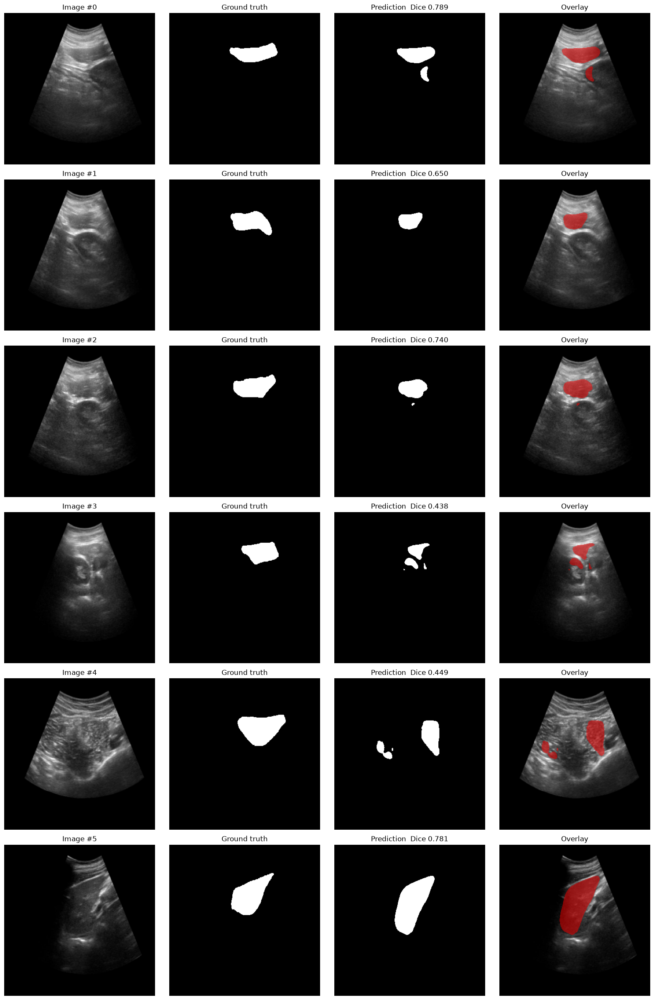

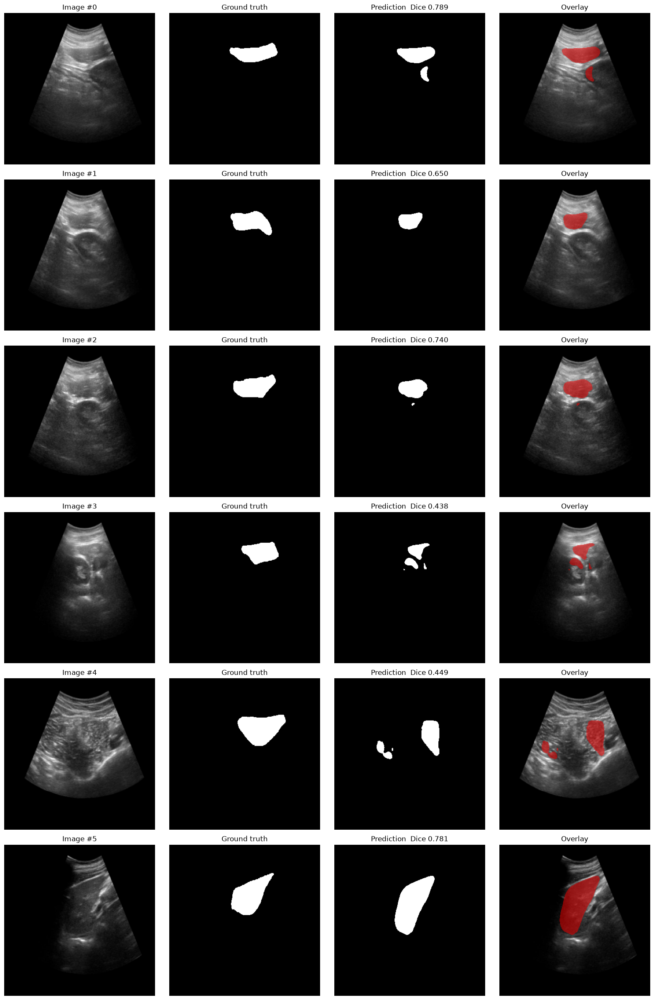

In [8]:
show_pairs(ROOT, model="E0")

## 2. Train Spleenex + sim&seg slices without spleen
Only 54 slices are available, so two models: 1) splx + simandseg, 2) splx + simandseg x3.
Both are tested on DeepSPV and Roboflow; Dice drops.

In [9]:
eval_sets()

Spleenex: loaded 450 samples (0 skipped)
Spleenex: spleen coverage 5.64%
Combined: 450 total samples
Split: 360 train / 90 test (total 450)
Split log saved: /raid/mpsych/SPLEENUS/runs/splits/Spleenex_seed42.json
DeepSPV: loaded 149 samples (0 skipped)
DeepSPV: spleen coverage 9.31%
Combined: 149 total samples
[SPLEENUS.DATA] train=['Spleenex'] (360 samples, val=90) | test=['DeepSPV'] (149 samples)
Spleenex: loaded 450 samples (0 skipped)
Spleenex: spleen coverage 5.64%
Combined: 450 total samples
Split: 360 train / 90 test (total 450)
Split log saved: /raid/mpsych/SPLEENUS/runs/splits/Spleenex_seed42.json
Roboflow: loaded 208 samples
Roboflow: spleen coverage 7.14%
Combined: 208 total samples
[SPLEENUS.DATA] train=['Spleenex'] (360 samples, val=90) | test=['Roboflow'] (208 samples)
model                        D       R     D+R | empty slices# D / R
Spleenex                 0.945   0.819   0.882 | 0 / 0
nnUNet environment set up at: /raid/mpsych/SPLEENUS/nnunet/nnunet_S_RUSneg_54
nnUNe

## 3. Visuals (random images, fixed seed)

Spleenex: loaded 450 samples (0 skipped)
Spleenex: spleen coverage 5.64%
Combined: 450 total samples
Split: 360 train / 90 test (total 450)
Split log saved: /raid/mpsych/SPLEENUS/runs/splits/Spleenex_seed42.json
DeepSPV: loaded 149 samples (0 skipped)
DeepSPV: spleen coverage 9.31%
Combined: 149 total samples
[SPLEENUS.DATA] train=['Spleenex'] (360 samples, val=90) | test=['DeepSPV'] (149 samples)


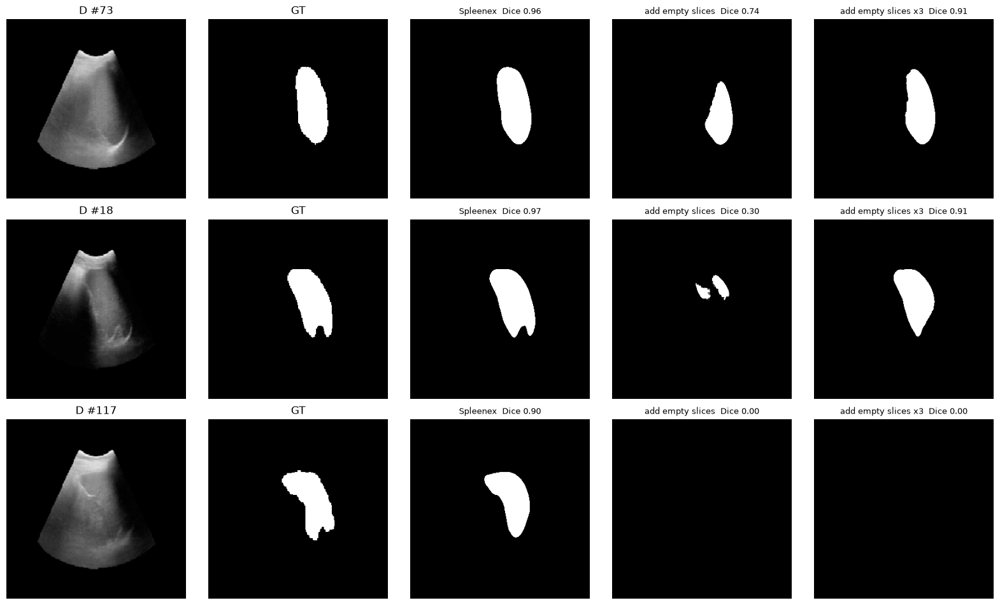

Spleenex: loaded 450 samples (0 skipped)
Spleenex: spleen coverage 5.64%
Combined: 450 total samples
Split: 360 train / 90 test (total 450)
Split log saved: /raid/mpsych/SPLEENUS/runs/splits/Spleenex_seed42.json
Roboflow: loaded 208 samples
Roboflow: spleen coverage 7.14%
Combined: 208 total samples
[SPLEENUS.DATA] train=['Spleenex'] (360 samples, val=90) | test=['Roboflow'] (208 samples)


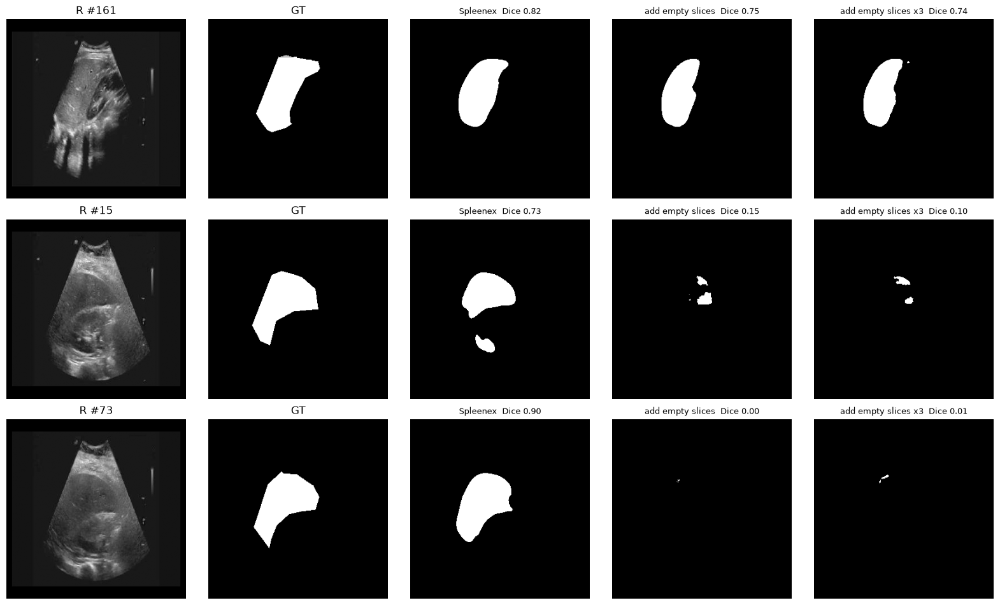

In [10]:
show_set("D", n=3)
show_set("R", n=3)

## 4. Our pilot data (no spleen - partial - full - partial - no)
No GT, so no Dice. Visual check only.

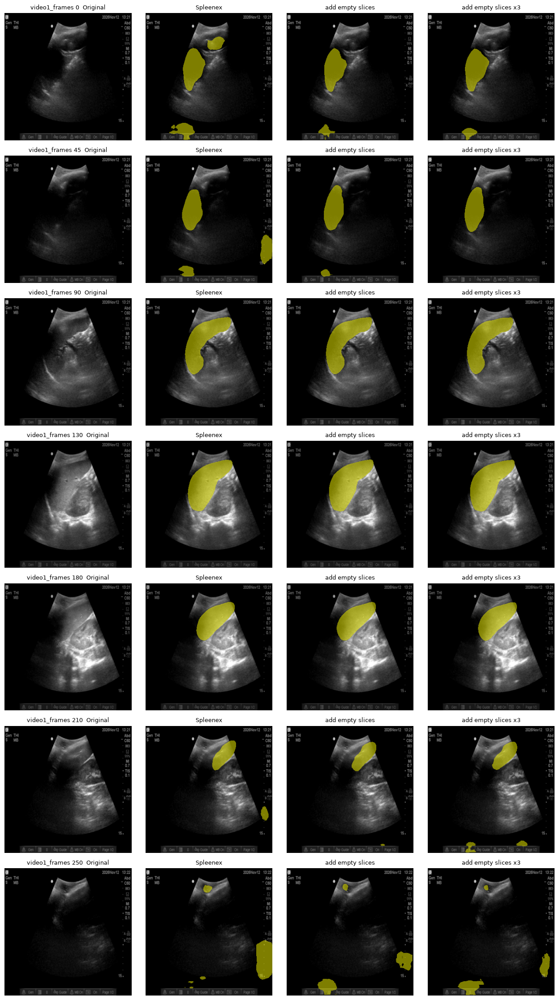

In [11]:
V4 = run_nnunet_video(VIDEOS[0])
show(V4, [0, 45, 90, 130, 180, 210, 250])

## 5. SAM3 tracker from the middle frame
Start mask = each nnUNet model's prediction on the middle frame. Propagate forward and backward.

frame loading (JPEG): 100%|█████████████████████████████████████████████| 251/251 [00:05<00:00, 45.42it/s]


propagate in video:   0%|          | 0/126 [00:00<?, ?it/s]

propagate in video:   0%|          | 0/126 [00:00<?, ?it/s]

frame loading (JPEG): 100%|█████████████████████████████████████████████| 251/251 [00:05<00:00, 45.66it/s]


propagate in video:   0%|          | 0/126 [00:00<?, ?it/s]

propagate in video:   0%|          | 0/126 [00:00<?, ?it/s]

frame loading (JPEG): 100%|█████████████████████████████████████████████| 251/251 [00:05<00:00, 48.04it/s]


propagate in video:   0%|          | 0/126 [00:00<?, ?it/s]

propagate in video:   0%|          | 0/126 [00:00<?, ?it/s]

video1_frames: 251 frames, start frame 125


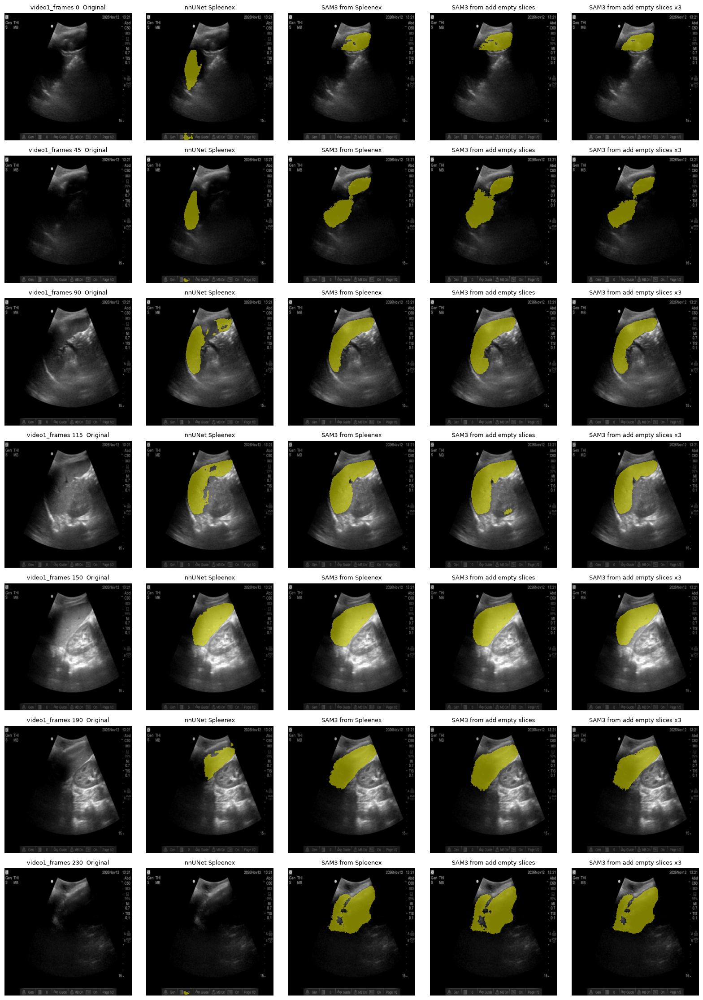

In [24]:
V10 = run_tracking(VIDEOS[0])
show(V10, IDS)

INFO 2026-11-25 16:15:19,882 2125626 sam3_video_base.py: 124: setting max_num_objects=10000 and num_obj_for_compile=16
frame loading (JPEG): 100%|█████████████████████████████████████████████| 231/231 [00:05<00:00, 45.62it/s]


propagate in video:   0%|          | 0/116 [00:00<?, ?it/s]

propagate in video:   0%|          | 0/116 [00:00<?, ?it/s]

frame loading (JPEG): 100%|█████████████████████████████████████████████| 231/231 [00:04<00:00, 46.73it/s]


propagate in video:   0%|          | 0/116 [00:00<?, ?it/s]

propagate in video:   0%|          | 0/116 [00:00<?, ?it/s]

frame loading (JPEG): 100%|█████████████████████████████████████████████| 231/231 [00:05<00:00, 46.04it/s]


propagate in video:   0%|          | 0/116 [00:00<?, ?it/s]

propagate in video:   0%|          | 0/116 [00:00<?, ?it/s]

video2_frames: 231 frames, start frame 115


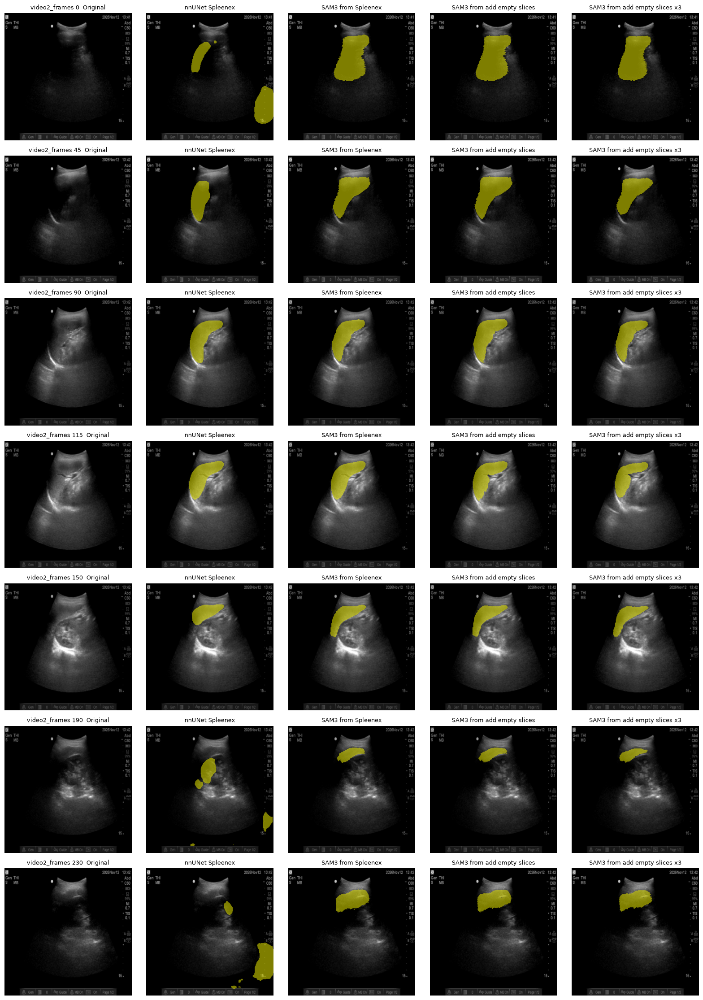

In [12]:
V5 = run_tracking(VIDEOS[1])
show(V5, IDS)
# show_all(V5)

frame loading (JPEG): 100%|█████████████████████████████████████████████| 242/242 [00:05<00:00, 45.89it/s]


propagate in video:   0%|          | 0/121 [00:00<?, ?it/s]

propagate in video:   0%|          | 0/122 [00:00<?, ?it/s]

frame loading (JPEG): 100%|█████████████████████████████████████████████| 242/242 [00:05<00:00, 46.45it/s]


propagate in video:   0%|          | 0/121 [00:00<?, ?it/s]

propagate in video:   0%|          | 0/122 [00:00<?, ?it/s]

frame loading (JPEG): 100%|█████████████████████████████████████████████| 242/242 [00:05<00:00, 45.47it/s]


propagate in video:   0%|          | 0/121 [00:00<?, ?it/s]

propagate in video:   0%|          | 0/122 [00:00<?, ?it/s]

video3_frames: 242 frames, start frame 121


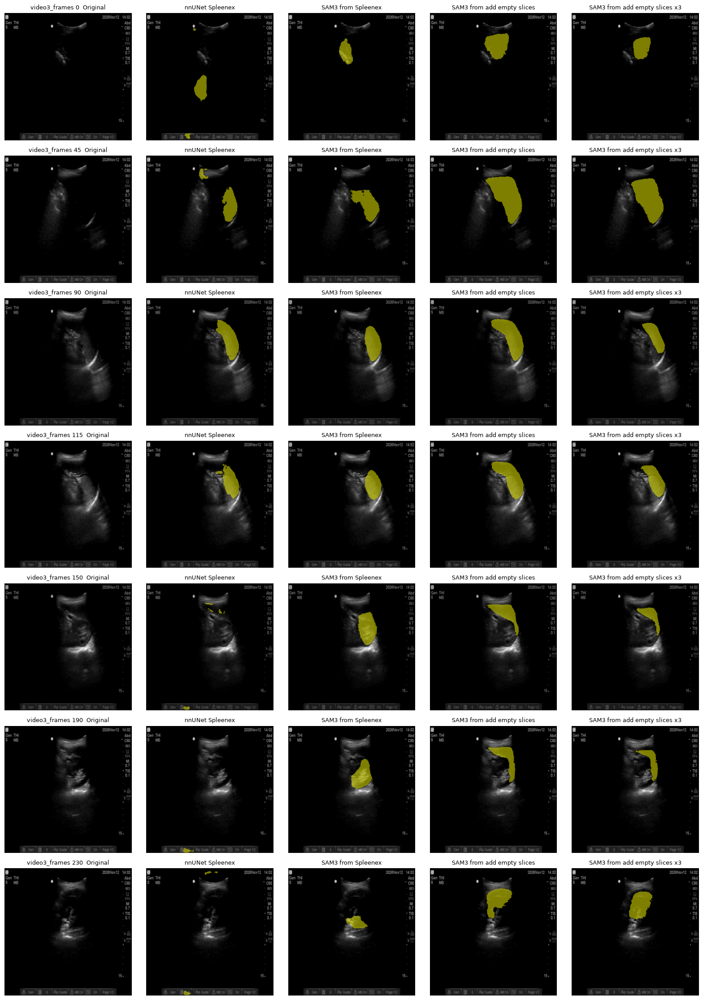

In [13]:
V6 = run_tracking(VIDEOS[2])
show(V6, IDS)

## 6. MedSAM3 checks

In [14]:
names_pos, X_pos, y_pos = load_pairs(f"{SIM}/RUS")             # 6 slices with spleen
names_neg, X_neg, y_neg = load_pairs(f"{SIM}/RUS_no_label")    # 54 slices without spleen

### 6-1. MedSAM3 baseline (text only): 6 spleen slices

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

[lora] replaced 61 nn.MultiheadAttention -> MultiheadAttentionLoRA
[lora] applied LoRA to 458 Linear layers
[lora] loaded LoRA weights from /home/jiehyun.kim001/.cache/huggingface/hub/models--lal-Joey--MedSAM3_v1/snapshots/f579e37e4db9f2c7e85a133b7970d59907e36fec/best_lora_weights.pt (916 tensors)
[medsam3] ready on cuda (weights: /home/jiehyun.kim001/.cache/huggingface/hub/models--lal-Joey--MedSAM3_v1/snapshots/f579e37e4db9f2c7e85a133b7970d59907e36fec/best_lora_weights.pt)
Dice: 0.2793 | IoU: 0.1623


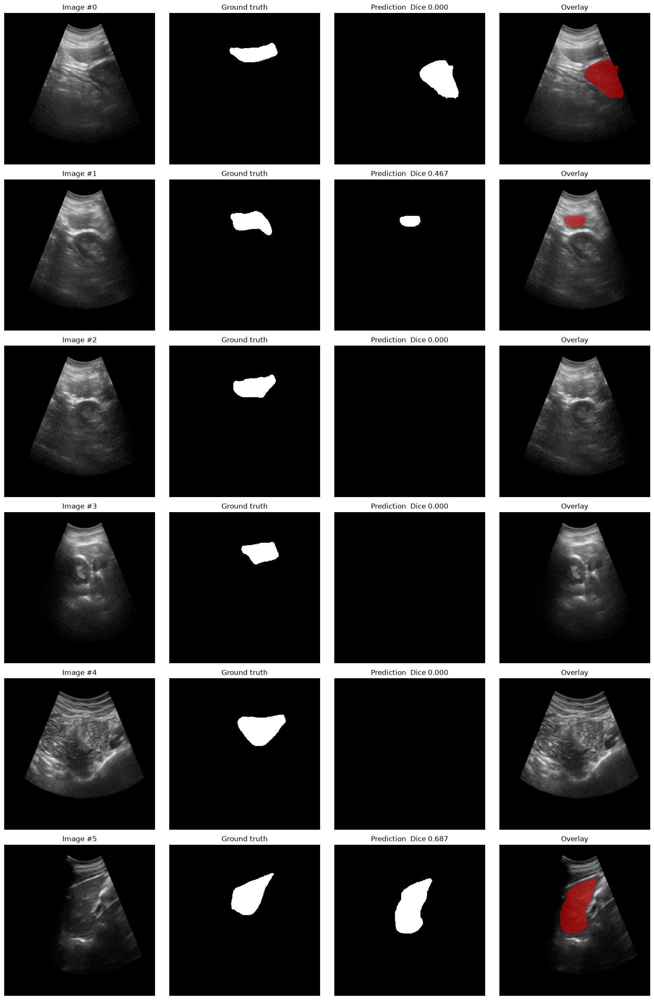

In [15]:
medsam = get_medsam()
metrics_medsam_base = evaluate(medsam, X_pos, y_pos)
visualize(medsam, X_pos, y_pos, n=6)

### 6-2. MedSAM3 baseline: 54 spleen-free slices
Dice is not defined when the GT is empty, so we count empty predictions.

empty predictions: 24/54 | false detections: 30/54
  person a: empty 7/12
  person b: empty 4/7
  person g: empty 3/9
  person h: empty 10/26


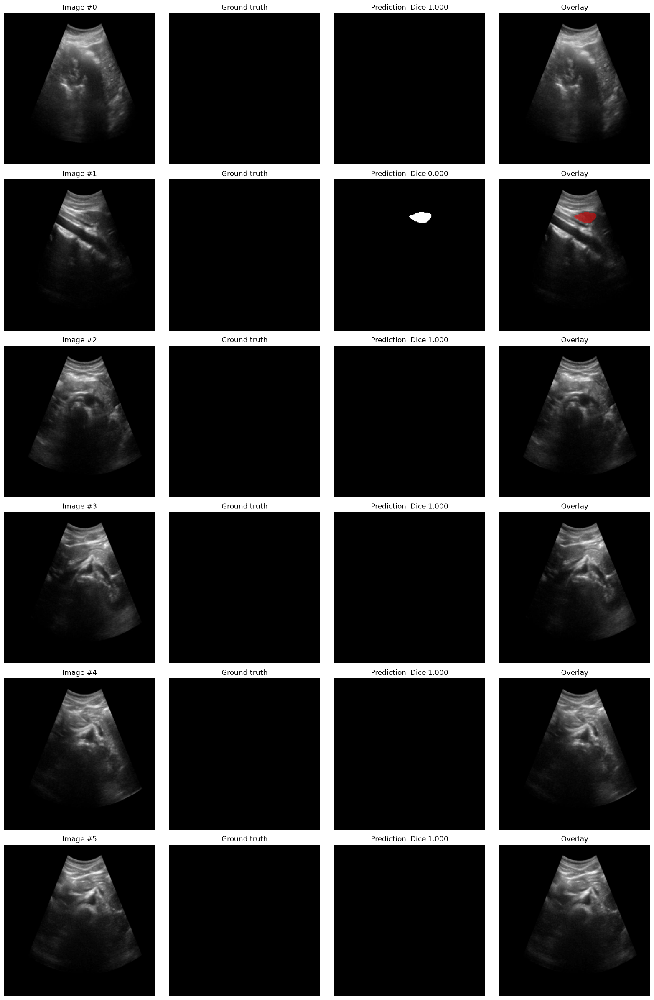

In [16]:
_ = count_empty(medsam, X_neg, names_neg)
visualize(medsam, X_neg, y_neg, n=6)

### 6-3. MedSAM3 fine-tuned on Spleenex

In [17]:
med_ft = get_medsam(MEDSAM_FT)
_ = evaluate(med_ft, X_pos, y_pos)
_ = count_empty(med_ft, X_neg, names_neg)

[lora] replaced 61 nn.MultiheadAttention -> MultiheadAttentionLoRA
[lora] applied LoRA to 458 Linear layers
[lora] loaded LoRA weights from /raid/mpsych/SPLEENUS/runs/medsam3_ft_S/best_lora_weights.pt (916 tensors)
[medsam3] ready on cuda (weights: /raid/mpsych/SPLEENUS/runs/medsam3_ft_S/best_lora_weights.pt)
Dice: 0.6804 | IoU: 0.5156
empty predictions: 0/54 | false detections: 54/54
  person a: empty 0/12
  person b: empty 0/7
  person g: empty 0/9
  person h: empty 0/26


### 6-4. MedSAM3 fine-tuned on Spleenex + 26 spleen-free slices from person h
Person h was used in training, so look at persons a, b, g.

In [18]:
med_neg = get_medsam(MEDSAM_HNEG)
_ = evaluate(med_neg, X_pos, y_pos)
_ = count_empty(med_neg, X_neg, names_neg)

[lora] replaced 61 nn.MultiheadAttention -> MultiheadAttentionLoRA
[lora] applied LoRA to 458 Linear layers
[lora] loaded LoRA weights from /raid/mpsych/SPLEENUS/runs/medsam3_ft_S_hneg/best_lora_weights.pt (916 tensors)
[medsam3] ready on cuda (weights: /raid/mpsych/SPLEENUS/runs/medsam3_ft_S_hneg/best_lora_weights.pt)
Dice: 0.0000 | IoU: 0.0000
empty predictions: 54/54 | false detections: 0/54
  person a: empty 12/12
  person b: empty 7/7
  person g: empty 9/9
  person h: empty 26/26


### 6-5. DeepSPV and Roboflow

In [19]:
eval_DR({"MedSAM3 FT": med_ft, "MedSAM3 FT + h-neg": med_neg})

model                        D       R
MedSAM3 FT               0.918   0.809
MedSAM3 FT + h-neg       0.022   0.817


### 6-6. Pilot videos, frame by frame

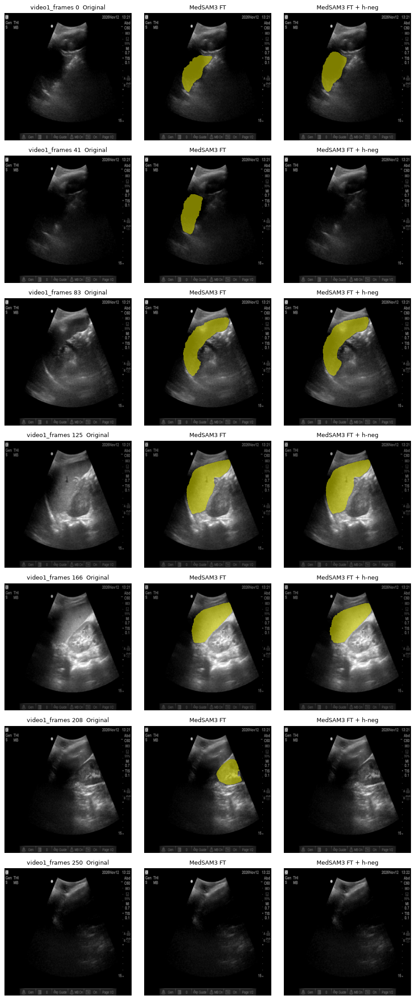

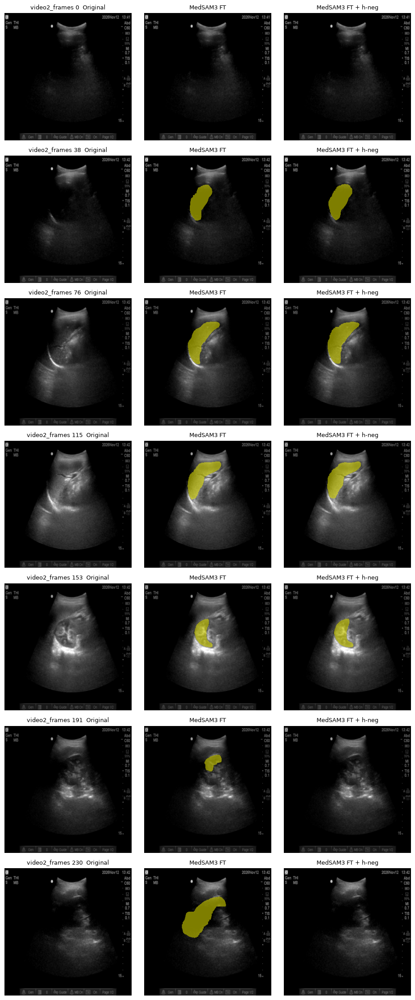

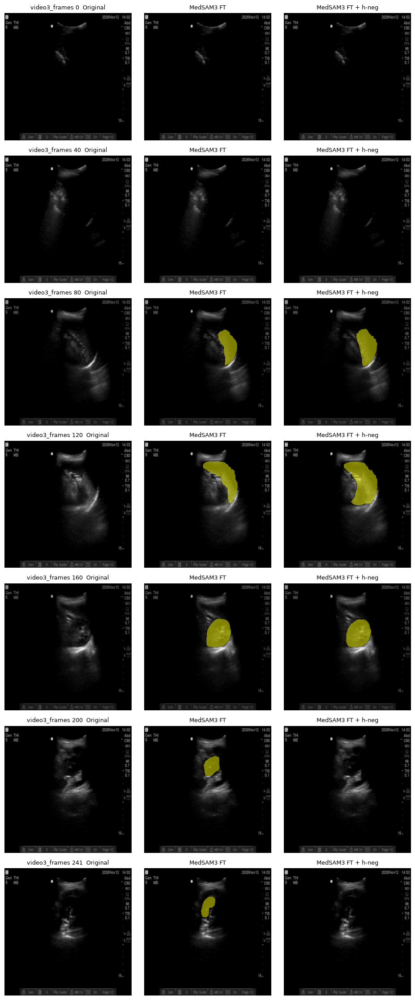

In [20]:
for F in VIDEOS:
    show(run_text_models(F, {"MedSAM3 FT": med_ft, "MedSAM3 FT + h-neg": med_neg}))

## 7. SAM3 detector + tracker
SAM3's own video mode: the detector (MedSAM3 FT LoRA, text 'spleen') finds the spleen in each frame,
the tracker carries it over time, and SAM3 merges both. Start from the middle frame.

frame loading (JPEG): 100%|█████████████████████████████████████████████| 251/251 [00:05<00:00, 46.21it/s]


propagate in video:   0%|          | 0/126 [00:00<?, ?it/s]

propagate in video:   0%|          | 0/126 [00:00<?, ?it/s]

INFO 2026-11-25 16:31:12,726 2125626 sam3_video_base.py: 124: setting max_num_objects=10000 and num_obj_for_compile=16


[lora] replaced 61 nn.MultiheadAttention -> MultiheadAttentionLoRA
[lora] applied LoRA to 458 Linear layers


frame loading (image folder) [rank=0]: 100%|████████████████████████████| 251/251 [00:03<00:00, 72.42it/s]


propagate_in_video:   0%|          | 0/126 [00:00<?, ?it/s]

propagate_in_video:   0%|          | 0/125 [00:00<?, ?it/s]

video1_frames: 251 frames, start frame 125


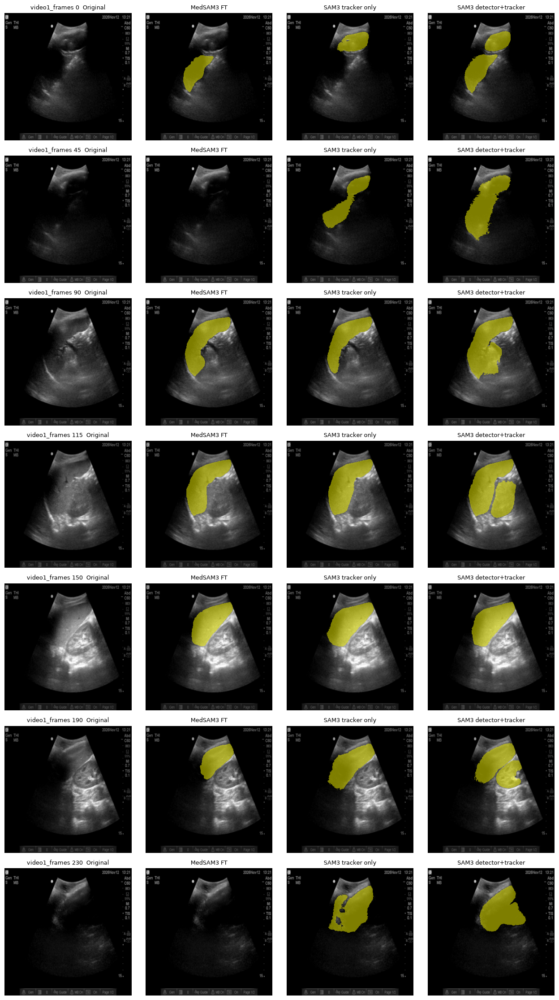

In [21]:
V7 = run_det_trk(VIDEOS[0]) 
show(V7, IDS)
# show_all(V7)

frame loading (JPEG): 100%|█████████████████████████████████████████████| 231/231 [00:04<00:00, 49.42it/s]


propagate in video:   0%|          | 0/116 [00:00<?, ?it/s]

propagate in video:   0%|          | 0/116 [00:00<?, ?it/s]

frame loading (image folder) [rank=0]: 100%|████████████████████████████| 231/231 [00:02<00:00, 77.91it/s]


propagate_in_video:   0%|          | 0/116 [00:00<?, ?it/s]

propagate_in_video:   0%|          | 0/115 [00:00<?, ?it/s]

video2_frames: 231 frames, start frame 115


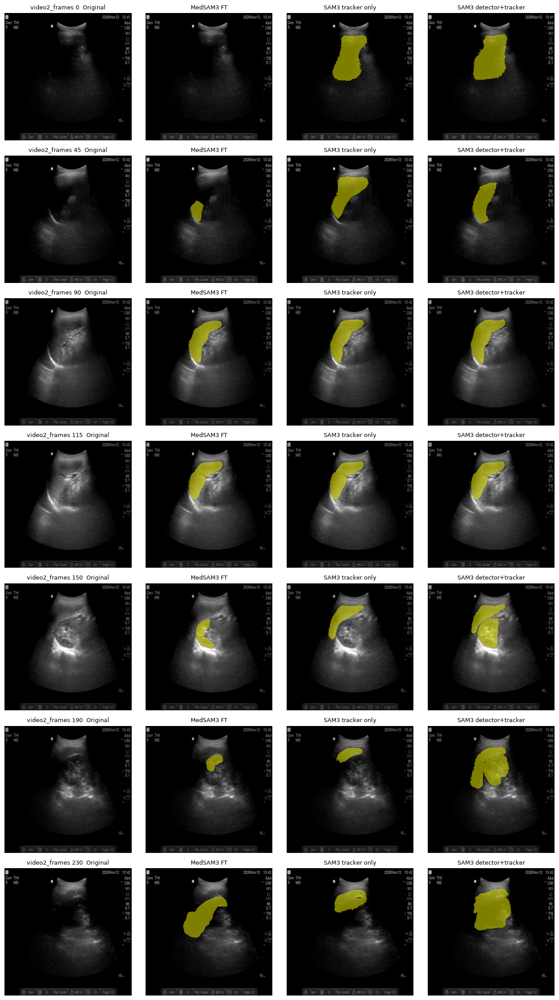

In [22]:
V8 = run_det_trk(VIDEOS[1]) 
show(V8, IDS)

frame loading (JPEG): 100%|█████████████████████████████████████████████| 242/242 [00:04<00:00, 49.62it/s]


propagate in video:   0%|          | 0/121 [00:00<?, ?it/s]

propagate in video:   0%|          | 0/122 [00:00<?, ?it/s]

frame loading (image folder) [rank=0]: 100%|████████████████████████████| 242/242 [00:03<00:00, 77.94it/s]


propagate_in_video:   0%|          | 0/121 [00:00<?, ?it/s]

propagate_in_video:   0%|          | 0/121 [00:00<?, ?it/s]

video3_frames: 242 frames, start frame 121


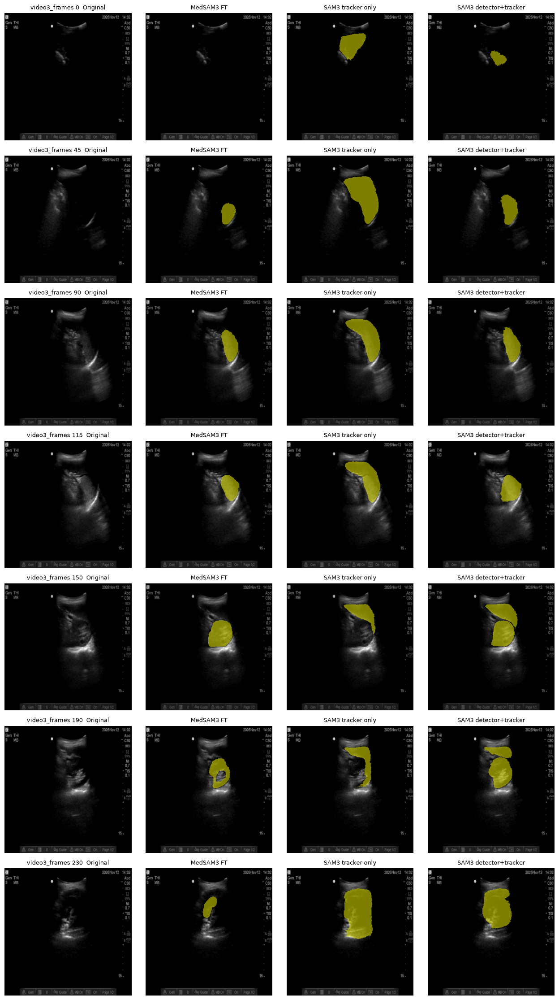

In [23]:
V9 = run_det_trk(VIDEOS[2]) 
show(V9, IDS)